# Analysis Human-Team (Phase II)

### Load and import

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import plotly.graph_objects as go
import plotly.io as pio
try:
    go.Figure().to_image(format="png")
    pio.renderers.default = "plotly_mimetype+png"
except Exception as e:
    print(f"Plotly PNG copies off ({type(e).__name__})")

from shared.data import Config, CountryMapper, OSV5MDataset, MetadataDecoder
from shared.models import GeoCLIPModel, PredictionRunner, Segmenter, TextDetector

from pair_a.q2_confidence import usable
from pair_a import q2_confidence_phase2 as q2p
from pair_a.q4_environment import add_env_columns
from pair_a import q4_environment_phase2 as q4p

cfg = Config()
mapper = CountryMapper("resources/country_aliases.csv")
dataset = OSV5MDataset(cfg, mapper).load()
decoder = MetadataDecoder()

run_name = f"streetclip_{cfg.candidate_list}_{cfg.crop_mode}"
preds, logits, embeds, info = PredictionRunner.load(f"results/shared/{run_name}")
preds = decoder.decode(preds)

out_dir = Path("results/pair_a/phase2")
(out_dir / "q2").mkdir(parents=True, exist_ok=True)
(out_dir / "q4").mkdir(parents=True, exist_ok=True)
print(f"{len(preds):,} predictions | model: {info['model']}")

/home/mut/projects/AI4VIS/ai_and_visualisation_OpenSI/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


210,122 predictions | model: geolocal/StreetCLIP


# Q1: Error structure and geography

# Q2: Overconfidence and training coverage

### Q2.1 Where do confident errors lie in the embedding space?
- kNN in StreetCLIP's image embeddings (k = 10, cosine similarity)
- Neighbours from the same camera sequence or closer than 50 km are skipped, otherwise kNN finds the same place
- References: at most 300 images per country, so big countries do not win the vote by size
- Queries: at most 50 images per country and group (correct / wrong x confident / unsure)
- Queries with fewer than 10 usable references of their own country are dropped (e.g. small islands where all images lie within 50 km)

kept 18,931 of 20,025 queries, 23 countries dropped completely


,n,countries,share_true,share_pred,vote_true,vote_pred,vote_pred_low,vote_pred_high
group,,,,,,,,
correct / confident,3116,107,0.727,0.727,0.873,0.873,0.861,0.884
correct / unsure,6603,162,0.448,0.448,0.581,0.581,0.569,0.592
wrong / confident,1600,117,0.310,0.360,0.356,0.447,0.423,0.471
wrong / unsure,7612,164,0.288,0.117,0.369,0.138,0.130,0.145


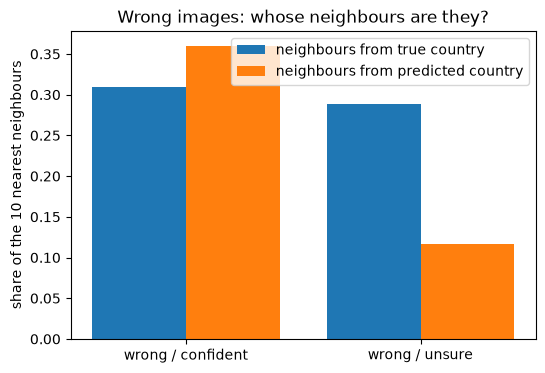

In [2]:
emb = q2p.load_embeddings(f"results/shared/{run_name}")
p = q2p.add_group(usable(preds))
ref = p.sample(frac=1, random_state=1).groupby("country_id").head(300)

q21 = p.sample(frac=1, random_state=42).groupby(["country_id", "group"]).head(50)
q21 = q2p.keep_reachable(ref, q21)
q21 = q2p.knn_columns(q21, q2p.neighbours(emb, ref, q21, min_km=50))
t21 = q2p.group_table(q21)
display(t21.round(3))
q2p.plot_groups(t21)

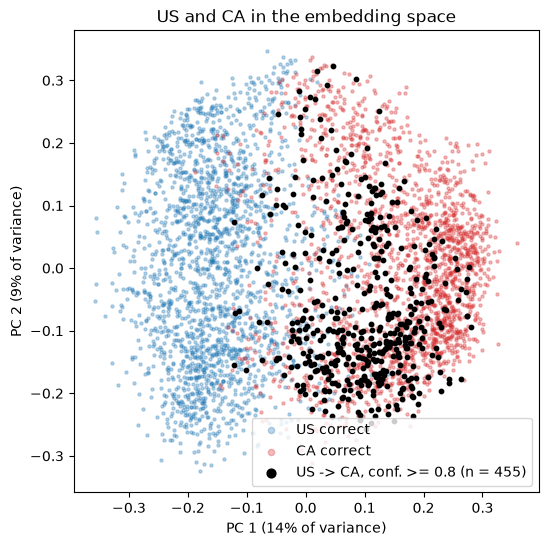

In [3]:
q2p.plot_pca_pair(emb, p, "US", "CA")

### Q2.2 Training coverage: CLIP vs. StreetCLIP embeddings
- Same kNN for both models, same queries (at most 100 per country) and references
- kNN accuracy: share of images whose neighbour vote is the true country
- If fine-tuning taught the list countries, their kNN accuracy should grow more from CLIP to StreetCLIP
- Scatter: kNN is hard on small countries (the 50 km rule leaves few own-country neighbours, border images of a neighbour are closer). So dots below the line are weak evidence, dots above the line are the robust signal

kept 15,154 of 16,388 queries, 23 countries dropped completely


countries: 84 on the list, 74 not on the list


,on_list_mean,off_list_mean,on_list_median,off_list_median,p_value
value,,,,,
knn_street,0.521,0.404,0.545,0.425,0.002
knn_clip,0.508,0.409,0.500,0.430,0.014
knn_gain,0.012,-0.005,0.010,0.000,0.068
zeroshot_gain,0.033,0.022,0.030,0.025,0.874


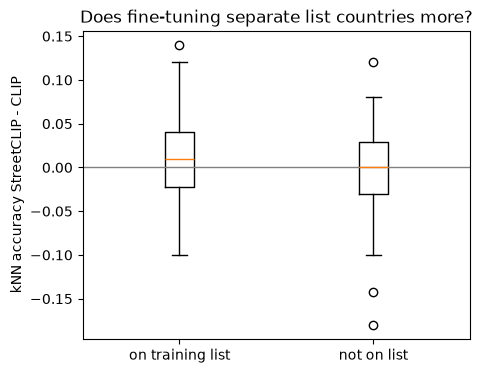

,n,zeroshot_street,zeroshot_clip,knn_street,knn_clip,knn_gain,zeroshot_gain,on_list,low_n
country_id,,,,,,,,,
GE,100,0.00,0.02,0.29,0.27,0.02,-0.02,False,False
CD,100,0.00,0.02,0.48,0.52,-0.04,-0.02,False,False
LT,100,0.02,0.06,0.24,0.25,-0.01,-0.04,True,False


In [4]:
preds_clip, _, _, _ = PredictionRunner.load("results/shared/clip_v1_center_crop")
emb_clip = q2p.load_embeddings("results/shared/clip_v1_center_crop")
p_clip = usable(preds_clip)

q22 = p.sample(frac=1, random_state=42).groupby("country_id").head(100)
q22 = q2p.keep_reachable(ref, q22)
q_street = q2p.knn_columns(q22, q2p.neighbours(emb, ref, q22, min_km=50))
q_clip = q2p.knn_columns(p_clip.loc[q22.index],
                         q2p.neighbours(emb_clip, p_clip.loc[ref.index], p_clip.loc[q22.index], min_km=50))
t22 = q2p.country_table(q_street, q_clip, mapper)
display(q2p.compare_lists(t22).round(3))
q2p.plot_gain(t22)
display(t22.loc[["GE", "CD", "LT"]].round(2))

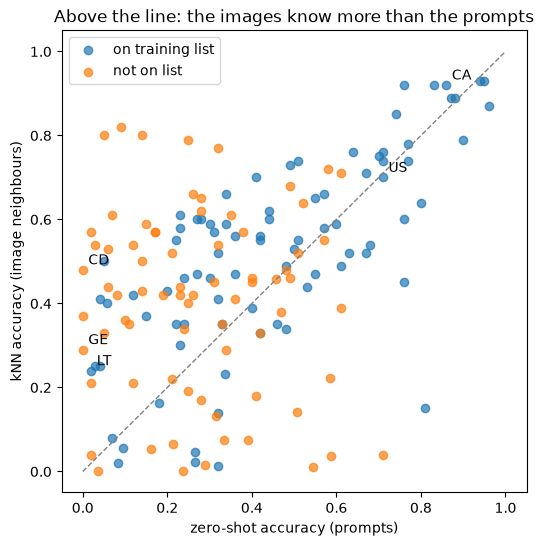

In [5]:
q2p.plot_text_gap(t22)

### Q2.3 Grad-CAM: confident errors vs. confident correct
- US images with confidence >= 0.8: guessed as Canada (all 455) vs. guessed correctly (455 drawn at random)
- Grad-CAM for the predicted country, last vision layer
- Share of the heat on each element (Mask2Former segments, same elements as Q3)

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 590/590 [00:00<00:00, 17998.82it/s]

,heat_wrong,heat_correct,area_wrong,area_correct,p_value
element,,,,,
road,0.318,0.373,0.251,0.252,0.000
vegetation,0.350,0.262,0.235,0.221,0.000
sky,0.226,0.294,0.369,0.435,0.000
buildings,0.027,0.011,0.020,0.007,0.000
vehicles,0.006,0.006,0.005,0.006,0.000
signs_poles,0.010,0.008,0.004,0.006,0.876


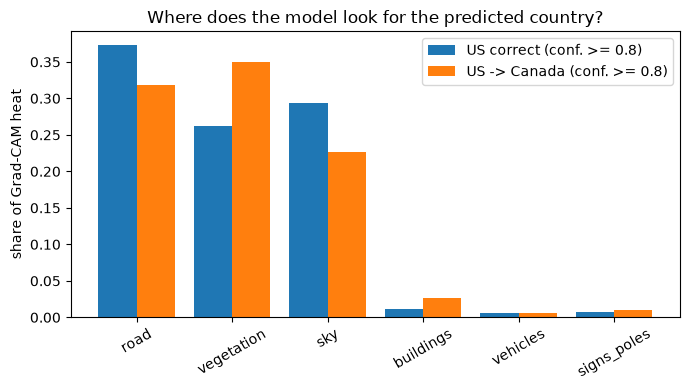

In [6]:
cfg.half_precision = False
geo = GeoCLIPModel(cfg.streetclip_model, cfg)
geo.set_candidates(info["labels"], mapper.prompts(info["labels"], cfg.prompt_template))
cam = q2p.make_cam(geo)

heat_file = out_dir / "q2" / "gradcam_us_canada.parquet"
us = p[(p["country_id"] == "US") & (p["prob_1"] >= 0.8)]
wrong = us[us["pred_1"] == "CA"].assign(group="US -> Canada")
right = us[us["pred_1"] == "US"].sample(len(wrong), random_state=42).assign(group="US correct")
rows = pd.concat([wrong, right])

if heat_file.exists():
    heat = pd.read_parquet(heat_file)
else:
    heat = q2p.heat_per_element(cam, geo, Segmenter(cfg), dataset, rows, cfg.crop_mode)
    heat = heat.merge(rows[["id", "group", "sequence"]], on="id")
    heat.to_parquet(heat_file)

t23 = q2p.element_table(heat, list(cfg.element_classes))
display(t23.round(3))
q2p.plot_elements(t23)

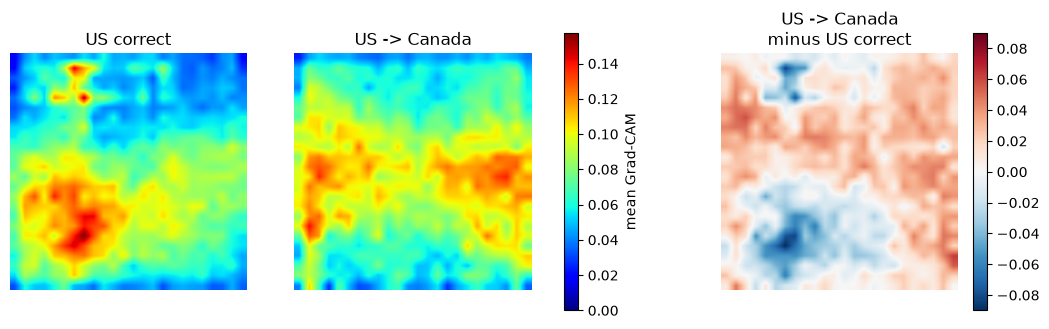

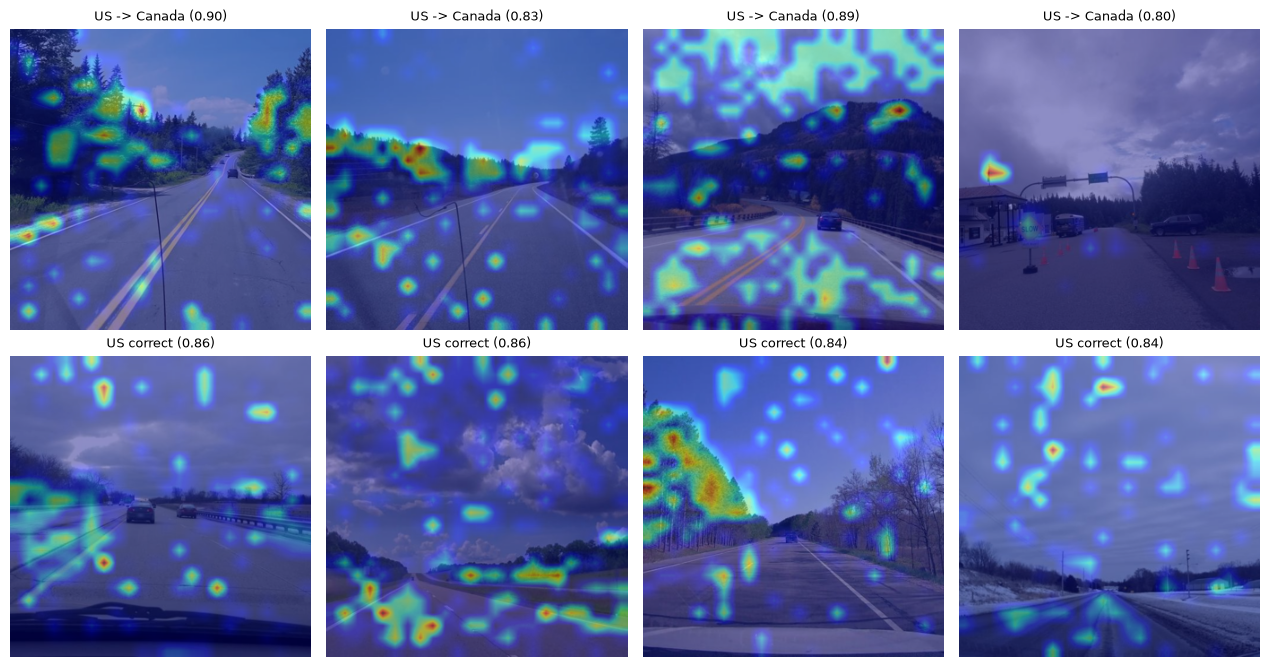

In [7]:
maps_file = out_dir / "q2" / "gradcam_mean_maps.npz"
if maps_file.exists():
    maps = np.load(maps_file)
else:
    maps = {"correct": q2p.mean_heatmap(cam, geo, dataset, rows[rows["group"] == "US correct"]),
            "wrong": q2p.mean_heatmap(cam, geo, dataset, rows[rows["group"] == "US -> Canada"])}
    np.savez(maps_file, **maps)
q2p.plot_mean_maps(maps["correct"], maps["wrong"], "US correct", "US -> Canada")
q2p.plot_examples(cam, geo, dataset, rows.sample(frac=1, random_state=1), cfg.crop_mode)

### Q2 findings
- **Confident errors look like the other country (Q2.1).** For wrong and confident images, the kNN vote is the predicted country in 44.7 % (CI 42.3 to 47.1, n = 1,600). For wrong and unsure images only 13.8 % (n = 7,612). In the PCA, the 455 confident US -> Canada errors sit inside the Canada cloud.
- **Training list still not confirmed (Q2.2).** List countries are better separated (kNN 52.1 % vs. 40.4 %, p = 0.002), but the original CLIP has the same gap (50.8 % vs. 40.9 %). Fine-tuning adds +1.2 vs. -0.5 points (p = 0.068). Same result as in Phase I.
- **Images vs. prompts (Q2.2).** Georgia: kNN 29 %, zero-shot 0 %. DR Congo: 48 % vs. 0 %. The images carry the country, the prompt does not find it. Lithuania is hard both ways (24 % vs. 2 %).
- **Vegetation for US -> Canada (Q2.3).** More Grad-CAM heat on vegetation (35.0 % vs. 26.2 %), less on the road (31.8 % vs. 37.3 %). The vegetation area is almost the same (23.5 % vs. 22.1 %), so it is focus, not more trees. The mean maps show heat at the image sides (forest) instead of the road. Fits Phase I Q3 (hiding vegetation: Canada -32.7 points).
- **Method notes**
  - First kNN version found the same place, not the country: macro kNN accuracy dropped from 64 % to 36 % with the 50 km rule. So same sequence and < 50 km are skipped.
  - References are capped at 300 per country, otherwise big countries win the vote.
  - 23 small countries (e.g. Bermuda, Tonga, Kuwait) have no usable references and are dropped.
- **Limits:** single pairs (e.g. Estonia -> Sweden) change with the reference set, so only groups are reported. Grad-CAM maps are spotty, only averages count. The high heat on the sky is probably a ViT artifact.

# Q3: Visual clues

# Q4: Environment

### Q4.1 Built-up vs. rural in the embedding space
- Phase I: built-up images are easier (+7.2 points within-country). Are they also more typical for their country?
- Same kNN as Q2 (k = 10, same sequence and < 50 km skipped, same references)
- Queries: at most 100 images per country for built-up and for rural / other
- Per country: built-up minus rural, only countries with at least 20 images in both

kept 19,953 of 21,187 queries, 23 countries dropped completely


,countries,mean,ci,share_above_0,p_value
value,,,,,
d_share_true,71,-0.040,0.040,0.479,0.127
d_knn_true,71,-0.039,0.048,0.451,0.229
d_correct,71,0.096,0.041,0.718,0.000


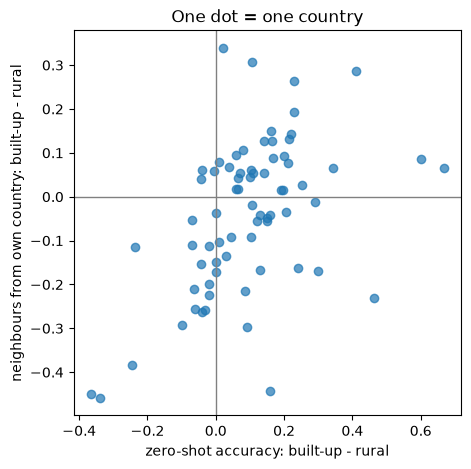

,countries,mean,ci,share_above_0,p_value
value,,,,,
d_share_true,51,-0.002,0.038,0.510,0.94
d_correct,51,0.111,0.036,0.843,0.00


In [8]:
env = add_env_columns(preds)
q41 = env[env["urban"].notna()].sample(frac=1, random_state=42).groupby(["country_id", "urban"]).head(100)
q41 = q2p.keep_reachable(ref, q41)
q41 = q2p.knn_columns(q41, q2p.neighbours(emb, ref, q41, min_km=50))
q41["knn_true"] = (q41["knn_vote"] == q41["country_id"]).astype(float)

d41 = q4p.urban_rural(q41)
display(q4p.summary(d41[["d_share_true", "d_knn_true", "d_correct"]]).round(3))
q4p.plot_urban(d41)

seq = q41.groupby(["country_id", "sequence", "urban"])[["share_true", "correct"]].mean().reset_index()
d_seq = q4p.urban_rural(seq, cols=("share_true", "correct"))
display(q4p.summary(d_seq[["d_share_true", "d_correct"]]).round(3))

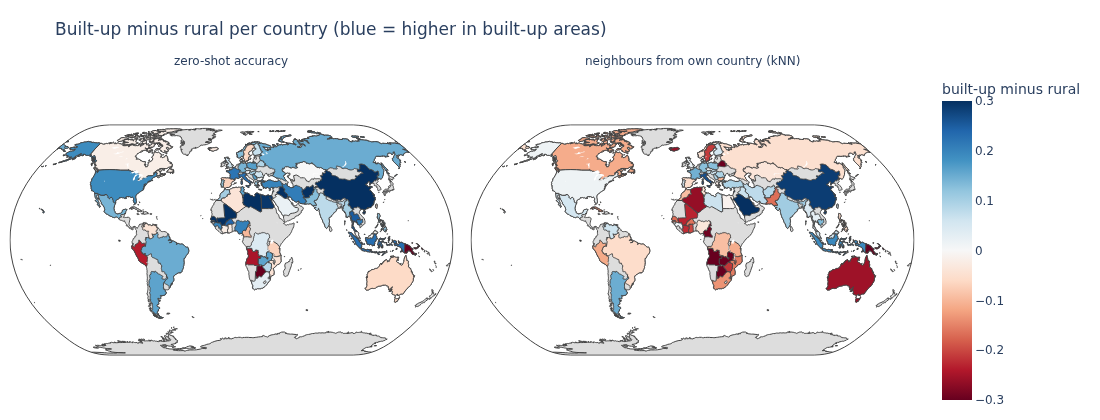

In [9]:
q4p.plot_urban_maps(d41, mapper.table)

### Q4.2 Climate and land cover in the embedding space
- Queries: at most 50 images per country and category
- Within-country difference as in Phase I: category minus the country's own value, averaged over countries
- Shown for the kNN value (neighbours from own country) and for zero-shot accuracy

kept 30,375 of 31,491 queries, 23 countries dropped completely


,countries,w_share_true,w_share_true_ci,images,w_correct,w_correct_ci
land_cover_name,,,,,,
water bodies,55,-0.039,0.027,2852,-0.014,0.033
tree covered,116,-0.018,0.016,5652,-0.046,0.021
sparse vegetation,30,-0.013,0.043,1560,-0.018,0.048
artificial surfaces,72,-0.010,0.034,3324,0.090,0.035
bare soil,42,-0.003,0.041,2061,-0.046,0.048
shrubs,64,0.004,0.022,3107,-0.026,0.024
"herbaceous, flooded",16,0.014,0.052,867,0.028,0.078
grassland,87,0.014,0.020,4269,-0.012,0.022
cropland,129,0.027,0.015,6370,0.022,0.015


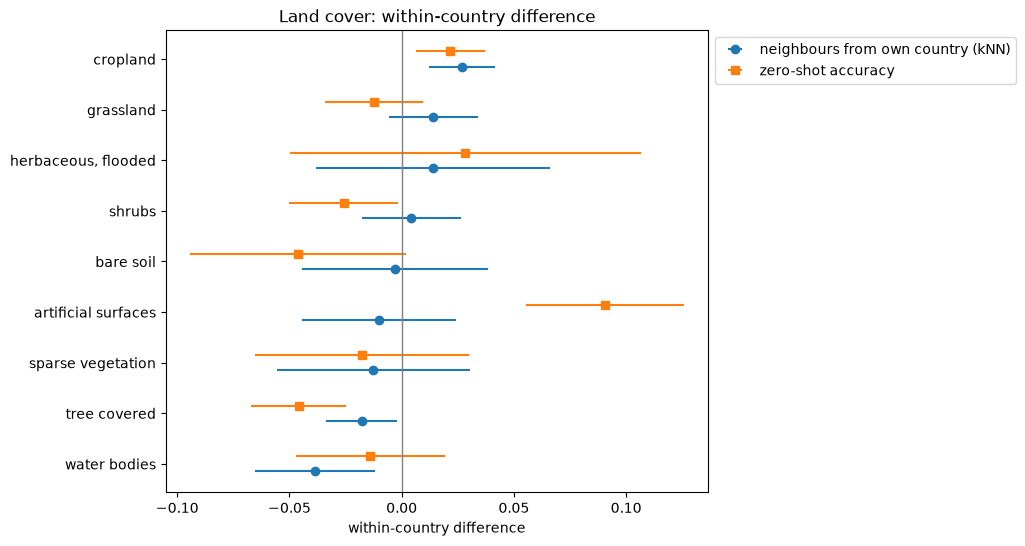

kept 13,982 of 14,849 queries, 23 countries dropped completely


,countries,w_share_true,w_share_true_ci,images,w_correct,w_correct_ci
climate_group,,,,,,
A tropical,75,-0.015,0.022,3708,-0.018,0.023
E polar,12,-0.008,0.083,617,-0.063,0.062
D continental,45,-0.005,0.025,2214,-0.001,0.031
C temperate,79,0.011,0.022,3929,0.018,0.027
B arid,71,0.014,0.023,3514,0.011,0.023


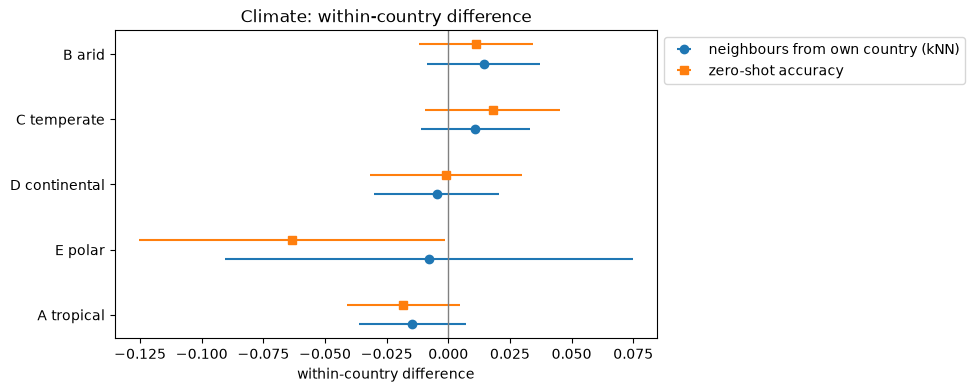

In [10]:
for var, title in [("land_cover_name", "Land cover"), ("climate_group", "Climate")]:
    q = env[env[var].notna()].sample(frac=1, random_state=42).groupby(["country_id", var]).head(50)
    q = q2p.keep_reachable(ref, q)
    q = q2p.knn_columns(q, q2p.neighbours(emb, ref, q, min_km=50))
    t = q4p.env_table(q, var)
    display(t.round(3))
    q4p.plot_env(t, f"{title}: within-country difference")

### Q4.3 Grad-CAM: built-up vs. rural
- Countries with at least 20 built-up and 20 rural images: 10 of each, drawn at random
- Grad-CAM for the true country
- Extra heat = heat share minus area share of an element; built-up minus rural inside each country
- Text from EasyOCR (as in Q3), the other elements from Mask2Former

,heat_built_up,heat_rural,d_heat,d_area,d_extra,d_extra_ci,p_value
element,,,,,,,
road,0.203,0.203,-0.000,0.010,-0.010,0.012,0.119
vegetation,0.174,0.240,-0.067,-0.059,-0.007,0.016,0.694
sky,0.362,0.381,-0.019,-0.034,0.015,0.019,0.157
buildings,0.086,0.033,0.053,0.053,0.000,0.008,0.928
vehicles,0.026,0.014,0.012,0.014,-0.003,0.004,0.045
signs_poles,0.020,0.008,0.012,0.012,-0.000,0.002,0.366
text,0.001,0.000,0.001,0.001,0.000,0.000,0.242


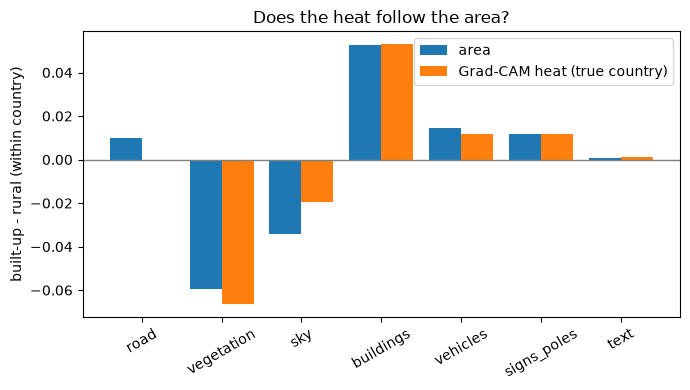

In [11]:
heat_file = out_dir / "q4" / "gradcam_urban_rural.parquet"
rows4 = q4p.gradcam_sample(env)

if heat_file.exists():
    heat4 = pd.read_parquet(heat_file)
else:
    heat4 = q2p.heat_per_element(cam, geo, Segmenter(cfg), dataset, rows4, cfg.crop_mode,
                                 target="country_id", text=TextDetector(cfg))
    heat4 = heat4.merge(rows4[["id", "country_id", "urban", "sequence", "correct"]], on="id")
    heat4.to_parquet(heat_file)

elements = list(cfg.element_classes) + ["text"]
t43 = q4p.heat_urban_rural(heat4, elements)
display(t43.round(3))
q4p.plot_heat(t43)

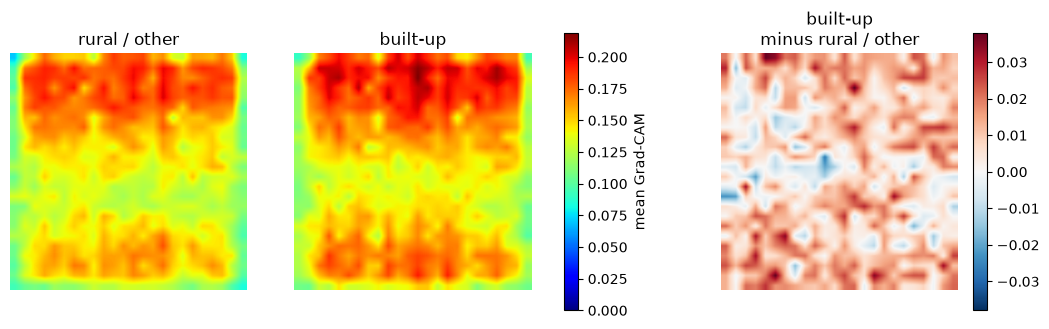

In [12]:
maps_file = out_dir / "q4" / "gradcam_mean_maps.npz"
if maps_file.exists():
    maps4 = np.load(maps_file)
else:
    maps4 = {"rural": q2p.mean_heatmap(cam, geo, dataset, rows4[rows4["urban"] == q4p.RURAL], target="country_id"),
             "urban": q2p.mean_heatmap(cam, geo, dataset, rows4[rows4["urban"] == q4p.URBAN], target="country_id")}
    np.savez(maps_file, **maps4)
q2p.plot_mean_maps(maps4["rural"], maps4["urban"], "rural / other", "built-up")

### Q4 findings
- **Built-up images are not more typical (Q4.1).** Zero-shot is +9.6 points better in built-up areas (+/- 4.1, 71 countries, p < 0.001). But the share of neighbours from the own country is -4.0 points (+/- 4.0, p = 0.13). With one value per sequence: +11.1 vs. -0.2. The two world maps show the same: mostly blue zero-shot map, mixed kNN map (red e.g. in Australia and southern Africa, where built-up images are less typical for their country).
- **Environment barely moves the embeddings (Q4.2).** Land cover: within-country kNN differences from -3.9 to +2.7 points. The zero-shot effects are larger (built-up +9.0, tree covered -4.6, bare soil -4.6). Climate: all within 1.5 points. Polar is -0.8 +/- 8.3 for kNN, but only 12 countries.
- **Heat follows the area (Q4.3).** Built-up images get more heat on buildings (+5.3 points), but also have more building area (+5.3). Extra heat is about 0 for every element. Text covers only ~0.1 % of the view, too rare to judge. The mean maps show no clear spatial difference.
- **Both techniques together:** the built-up advantage is not in the images (kNN) and not in where the model looks (Grad-CAM). So it is probably on the prompt side, like Georgia in Q2.2. This is an open point, not proven.
- **Limits:** built-up is the land cover proxy from Phase I. kNN is hard on small countries (50 km rule). Sky heat is probably an artifact.